In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!git clone https://github.com/hiiba8/drug-review-lstm.git
%cd drug-review-lstm
!mkdir -p data
!cp /content/drive/MyDrive/drug_review/*.csv data/
!pip install -q pandas scikit-learn
!python train.py --cell cifg --sample 1000 --epochs 1
!rm -f results.csv

Cloning into 'drug-review-lstm'...
remote: Enumerating objects: 16, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 16 (delta 0), reused 13 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (16/16), 6.72 KiB | 6.72 MiB/s, done.
/content/drug-review-lstm
device: cuda
cifg: 800,771 paramètres
ep1 train_loss 1.099 | val_loss 1.096 val_acc 0.350 val_f1 0.290
TEST acc 0.335 | F1 macro 0.283
[[28 10 12]
 [ 7  3  8]
 [75 21 36]]


In [ ]:
import os, shutil, pandas as pd
OUT = "/content/drive/MyDrive/drug_review/out"
os.makedirs(OUT, exist_ok=True)
if os.path.exists(f"{OUT}/results.csv"):
    shutil.copy(f"{OUT}/results.csv", "results.csv")

def done_runs():
    if not os.path.exists("results.csv"): return set()
    d = pd.read_csv("results.csv")
    return set(d[d["sample"].isna()]["run"])   # ignore les runs de test

runs = [  # (cell, lr, opt, bs, init)
    ("vanilla", 1e-3, "adam", 64, "default"),
    ("cifg",    1e-3, "adam", 64, "default"),
    ("lstmp",   1e-3, "adam", 64, "default"),
]
for cell, lr, opt, bs, init in runs:
    name = f"{cell}_lr{lr}_{opt}_bs{bs}_{init}"
    if name in done_runs():
        print("déjà fait :", name); continue
    cmd = f"python train.py --cell {cell} --lr {lr} --opt {opt} --bs {bs} --init {init} --epochs 8"
    !{cmd}
    shutil.copy("results.csv", f"{OUT}/results.csv")
    if os.path.exists("checkpoints"):
        shutil.copytree("checkpoints", f"{OUT}/checkpoints", dirs_exist_ok=True)

device: cuda
vanilla: 2,691,971 paramètres
ep1 train_loss 0.899 | val_loss 0.732 val_acc 0.684 val_f1 0.583
ep2 train_loss 0.742 | val_loss 0.618 val_acc 0.742 val_f1 0.633
ep3 train_loss 0.632 | val_loss 0.641 val_acc 0.741 val_f1 0.641
ep4 train_loss 0.530 | val_loss 0.574 val_acc 0.766 val_f1 0.664
ep5 train_loss 0.443 | val_loss 0.531 val_acc 0.800 val_f1 0.698
ep6 train_loss 0.364 | val_loss 0.552 val_acc 0.807 val_f1 0.709
ep7 train_loss 0.299 | val_loss 0.514 val_acc 0.835 val_f1 0.740
ep8 train_loss 0.251 | val_loss 0.522 val_acc 0.844 val_f1 0.753
TEST acc 0.845 | F1 macro 0.754
[[11422  1023  1052]
 [  901  2973   955]
 [ 2221  2169 31050]]
device: cuda
cifg: 2,659,075 paramètres
ep1 train_loss 0.878 | val_loss 0.642 val_acc 0.726 val_f1 0.612
ep2 train_loss 0.706 | val_loss 0.695 val_acc 0.685 val_f1 0.609
ep3 train_loss 0.593 | val_loss 0.593 val_acc 0.754 val_f1 0.655
ep4 train_loss 0.488 | val_loss 0.553 val_acc 0.793 val_f1 0.691
ep5 train_loss 0.396 | val_loss 0.561 val

In [ ]:
import os, shutil, pandas as pd
OUT = "/content/drive/MyDrive/drug_review/out"
os.makedirs(OUT, exist_ok=True)
if os.path.exists(f"{OUT}/results.csv"):
    shutil.copy(f"{OUT}/results.csv", "results.csv")

def done_runs():
    if not os.path.exists("results.csv"): return set()
    d = pd.read_csv("results.csv")
    return set(d[d["sample"].isna()]["run"])

runs = [
    ("vanilla", 1e-3, "adam", 64, "default"),
    ("cifg",    1e-3, "adam", 64, "default"),
    ("lstmp",   1e-3, "adam", 64, "default"),
    ("vanilla", 1e-2, "adam", 64, "default"),
    ("vanilla", 1e-3, "rmsprop", 64, "default"),
    ("vanilla", 1e-3, "adam", 128, "default"),
    ("vanilla", 1e-3, "adam", 64, "xavier"),
]
for cell, lr, opt, bs, init in runs:
    name = f"{cell}_lr{lr}_{opt}_bs{bs}_{init}"
    if name in done_runs():
        print("déjà fait :", name); continue
    cmd = f"python train.py --cell {cell} --lr {lr} --opt {opt} --bs {bs} --init {init} --epochs 8"
    !{cmd}
    shutil.copy("results.csv", f"{OUT}/results.csv")
    if os.path.exists("checkpoints"):
        shutil.copytree("checkpoints", f"{OUT}/checkpoints", dirs_exist_ok=True)

déjà fait : vanilla_lr0.001_adam_bs64_default
déjà fait : cifg_lr0.001_adam_bs64_default
déjà fait : lstmp_lr0.001_adam_bs64_default
device: cuda
vanilla: 2,691,971 paramètres
ep1 train_loss 0.951 | val_loss 0.754 val_acc 0.681 val_f1 0.549
ep2 train_loss 0.914 | val_loss 0.809 val_acc 0.648 val_f1 0.534
ep3 train_loss 0.913 | val_loss 0.894 val_acc 0.598 val_f1 0.516
ep4 train_loss 0.923 | val_loss 0.867 val_acc 0.606 val_f1 0.507
ep5 train_loss 0.942 | val_loss 0.834 val_acc 0.644 val_f1 0.512
ep6 train_loss 0.955 | val_loss 0.838 val_acc 0.629 val_f1 0.504
ep7 train_loss 0.955 | val_loss 0.929 val_acc 0.565 val_f1 0.478
ep8 train_loss 0.966 | val_loss 0.845 val_acc 0.643 val_f1 0.495
TEST acc 0.684 | F1 macro 0.553
[[ 8807  2739  1951]
 [ 1658  1553  1618]
 [ 3656  5385 26399]]
device: cuda
vanilla: 2,691,971 paramètres
ep1 train_loss 0.895 | val_loss 0.802 val_acc 0.641 val_f1 0.562
ep2 train_loss 0.753 | val_loss 0.674 val_acc 0.711 val_f1 0.615
ep3 train_loss 0.659 | val_loss 0.5

In [ ]:
# Le nom du run inclut la seed (sauf pour 42, pour garder les anciens noms)
s = open("train.py").read()
old = 'name = f"{a.cell}_lr{a.lr}_{a.opt}_bs{a.bs}_{a.init}"'
new = old + ' + (f"_s{a.seed}" if a.seed != 42 else "")'
if new not in s:
    assert old in s, "ligne name introuvable dans train.py"
    open("train.py", "w").write(s.replace(old, new))

import os, shutil, pandas as pd
OUT = "/content/drive/MyDrive/drug_review/out"
os.makedirs(OUT, exist_ok=True)
if os.path.exists(f"{OUT}/results.csv"):
    shutil.copy(f"{OUT}/results.csv", "results.csv")

def done_runs():
    if not os.path.exists("results.csv"): return set()
    d = pd.read_csv("results.csv")
    return set(d[d["sample"].isna()]["run"])

runs = [
    ("vanilla", 1e-3, "adam", 64, "default", 7),
    ("cifg",    1e-3, "adam", 64, "default", 7),
]
for cell, lr, opt, bs, init, seed in runs:
    name = f"{cell}_lr{lr}_{opt}_bs{bs}_{init}" + (f"_s{seed}" if seed != 42 else "")
    if name in done_runs():
        print("déjà fait :", name); continue
    cmd = f"python train.py --cell {cell} --lr {lr} --opt {opt} --bs {bs} --init {init} --seed {seed} --epochs 8"
    !{cmd}
    shutil.copy("results.csv", f"{OUT}/results.csv")
    if os.path.exists("checkpoints"):
        shutil.copytree("checkpoints", f"{OUT}/checkpoints", dirs_exist_ok=True)

device: cuda
vanilla: 2,691,971 paramètres
ep1 train_loss 0.902 | val_loss 0.787 val_acc 0.632 val_f1 0.561
ep2 train_loss 0.738 | val_loss 0.652 val_acc 0.718 val_f1 0.621
ep3 train_loss 0.630 | val_loss 0.614 val_acc 0.745 val_f1 0.648
ep4 train_loss 0.527 | val_loss 0.536 val_acc 0.792 val_f1 0.688
ep5 train_loss 0.435 | val_loss 0.545 val_acc 0.795 val_f1 0.698
ep6 train_loss 0.356 | val_loss 0.518 val_acc 0.819 val_f1 0.724
ep7 train_loss 0.287 | val_loss 0.562 val_acc 0.818 val_f1 0.727
ep8 train_loss 0.240 | val_loss 0.514 val_acc 0.845 val_f1 0.755
TEST acc 0.847 | F1 macro 0.757
[[10922  1271  1304]
 [  690  3211   928]
 [ 1611  2449 31380]]
device: cuda
cifg: 2,659,075 paramètres
ep1 train_loss 0.874 | val_loss 0.732 val_acc 0.690 val_f1 0.599
ep2 train_loss 0.698 | val_loss 0.598 val_acc 0.742 val_f1 0.645
ep3 train_loss 0.582 | val_loss 0.604 val_acc 0.754 val_f1 0.658
ep4 train_loss 0.475 | val_loss 0.568 val_acc 0.781 val_f1 0.687
ep5 train_loss 0.379 | val_loss 0.506 val

                                 run  params  val_f1  test_acc  test_f1  minutes
   vanilla_lr0.001_adam_bs64_default 2691971  0.7534    0.8452   0.7540     34.0
      cifg_lr0.001_adam_bs64_default 2659075  0.7573    0.8492   0.7611     36.7
     lstmp_lr0.001_adam_bs64_default 2667267  0.7495    0.8416   0.7488     39.9
    vanilla_lr0.01_adam_bs64_default 2691971  0.5485    0.6837   0.5530     34.9
vanilla_lr0.001_rmsprop_bs64_default 2691971  0.7457    0.8422   0.7464     34.3
  vanilla_lr0.001_adam_bs128_default 2691971  0.7314    0.8199   0.7294     17.0
    vanilla_lr0.001_adam_bs64_xavier 2691971  0.7499    0.8434   0.7531     33.5
vanilla_lr0.001_adam_bs64_default_s7 2691971  0.7547    0.8465   0.7575     34.3
   cifg_lr0.001_adam_bs64_default_s7 2659075  0.7604    0.8491   0.7603     37.2


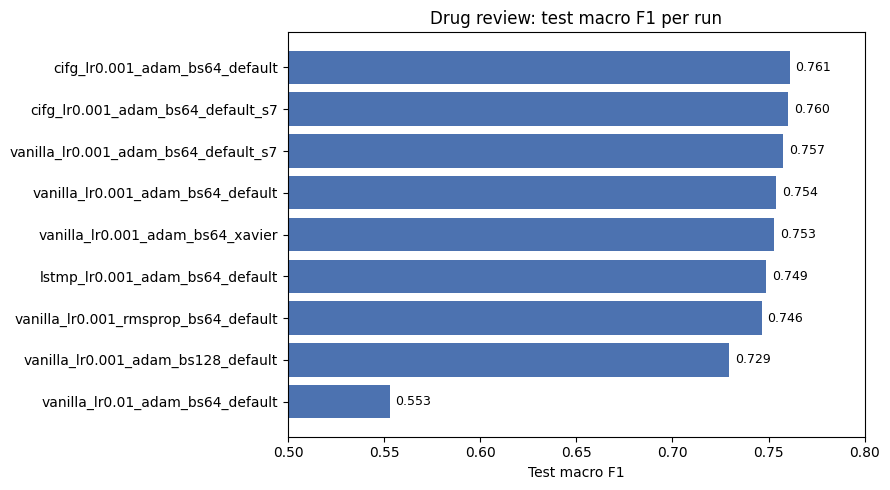

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

d = pd.read_csv("results.csv")
d = d[d["sample"].isna()].copy()
print(d[["run", "params", "val_f1", "test_acc", "test_f1", "minutes"]].to_string(index=False))

# Graphique : F1 macro test de chaque run
d = d.sort_values("test_f1")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(d["run"], d["test_f1"], color="#4C72B0")
for y, v in enumerate(d["test_f1"]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("Test macro F1")
ax.set_xlim(0.5, 0.8)
ax.set_title("Drug review: test macro F1 per run")
plt.tight_layout()
plt.savefig("f1_comparison.png", dpi=200)
plt.show()

files.download("results.csv")
files.download("f1_comparison.png")

Mounted at /content/drive
/content/drive/MyDrive/drug_review/drugsComTrain_raw.csv


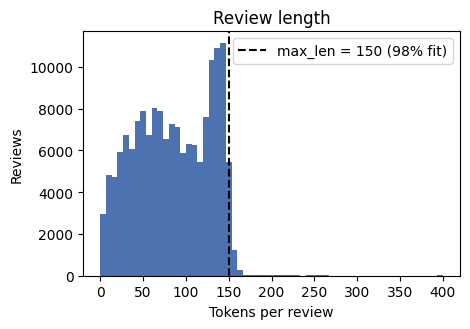

count    161297.0
mean         84.7
std          45.2
min           0.0
25%          48.0
50%          84.0
75%         126.0
max        1918.0
Name: review, dtype: float64


In [1]:
from google.colab import drive; drive.mount('/content/drive')
import pandas as pd, re, glob, matplotlib.pyplot as plt
f = glob.glob('/content/drive/MyDrive/**/drugsComTrain_raw.*', recursive=True)[0]; print(f)
df = pd.read_csv(f, sep='\t' if f.endswith('tsv') else ',')
tok = lambda t: re.findall(r"[a-z']+", re.sub(r"&#039;|&quot;|<[^>]+>", " ", str(t).lower()))
L = df['review'].apply(lambda t: len(tok(t)))
plt.figure(figsize=(4.8,3.4)); plt.hist(L.clip(upper=400), bins=60, color='#4C72B0')
plt.axvline(150, ls='--', color='black', label=f'max_len = 150 ({(L<=150).mean()*100:.0f}% fit)')
plt.xlabel('Tokens per review'); plt.ylabel('Reviews'); plt.title('Review length'); plt.legend()
plt.tight_layout(); plt.savefig('fig2_lengths.png', dpi=200); plt.show(); print(L.describe().round(1))